# Universal Free School Meals and Educational Outcomes
Code generated with assistance from ChatGPT (OpenAI, 2026)

# Data Cleaning

## Setup

In [1]:
# import packages
import pandas as pd
import numpy as np

## Clean School Meal Datasets

In [2]:
# load in school meal datasets
meal_2014_15_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/School%20Meals%202014-2015.csv")
meal_2015_16_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/School%20Meals%202015-2016.csv")
meal_2016_17_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/School%20Meals%202016-2017.csv")
meal_2017_18_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/School%20Meals%202017-2018.csv")
meal_2018_19_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/School%20Meals%202018-2019.csv")

In [3]:
# # load in school meal datasets
# meal_2014_15_df = pd.read_csv("School Meals 2014-2015.csv")
# meal_2015_16_df = pd.read_csv("School Meals 2015-2016.csv")
# meal_2016_17_df = pd.read_csv("School Meals 2016-2017.csv")
# meal_2017_18_df = pd.read_csv("School Meals 2017-2018.csv")
# meal_2018_19_df = pd.read_csv("School Meals 2018-2019.csv")

In [4]:
# create dataframe list to manipulate simultaneously
meal_list = [
    meal_2014_15_df,
    meal_2015_16_df,
    meal_2016_17_df,
    meal_2017_18_df,
    meal_2018_19_df
]

In [5]:
# drop empty columns
for meal_year_df in meal_list:
    meal_year_df.drop(
        columns=["Unnamed: 1", "Unnamed: 3"],
        inplace=True,
        errors="ignore"
    )

In [6]:
# rename columns
for meal_year_df in meal_list:
    meal_year_df = meal_year_df.rename(columns={
        "County": "county_name",
        "Agreement Number": "aun",
        "Sponsor": "district_name",
        "Sponsor Type": "district_type",
        "Site No.": "school_id",
        "Building No.": "school_id",
        "Building Name": "school_name",
        "Building Street": "school_address",
        "Building City": "school_city",
        "Building State": "school_state",
        "Building State": "school_state",
        "Building Zip": "school_zip",
        "CEP": "cep",
        "E": "early_childhood",
        "PK": "pre_k",
        "K": "kindergarten",
        "1": "grade_one",
        "2": "grade_two",
        "3": "grade_three",
        "4": "grade_four",
        "5": "grade_five",
        "6": "grade_six",
        "7": "grade_seven",
        "8": "grade_eight",
        "9": "grade_nine",
        "10": "grade_ten",
        "0": "grade_ten",
        "11": "grade_eleven",
        "1.1": "grade_eleven",
        "12": "grade_twelve",
        "2.1": "grade_twelve",
        "Enrollment": "total_student_count",
        " Enrollment ": "total_student_count",
        "Free\nEligible": "free_count",
        "Free\r\nEligible": "free_count",
        " Free\r\nEligible ": "free_count",
        "Reduced\nEligible": "reduced_count",
        "Reduced\r\nEligible": "reduced_count",
        " Reduced\r\nEligible ": "reduced_count",
        "% Free\nEnrollment": "free_pct",
        "% Free\r\nEnrollment": "free_pct",
        "% Reduced\nEnrollment": "reduced_pct",
        "% Reduced\r\nEnrollment": "reduced_pct",
        "% Free/\nReduced\nEnrollment": "free_reduced_pct",
        "% Free / Reduced\r\nEnrollment": "free_reduced_pct"
    }, inplace=True)

In [7]:
# convert school id and name to strings
for meal_year_df in meal_list:
    meal_year_df["school_id"] = meal_year_df["school_id"].astype("string").str.strip()
    meal_year_df["school_name"] = meal_year_df["school_name"].astype("string")

In [8]:
# convert grade levels to strings
for meal_year_df in meal_list:
    meal_year_df["early_childhood"] = meal_year_df["early_childhood"].astype("string")
    meal_year_df["pre_k"] = meal_year_df["pre_k"].astype("string")
    meal_year_df["kindergarten"] = meal_year_df["kindergarten"].astype("string")
    meal_year_df["grade_one"] = meal_year_df["grade_one"].astype("string")
    meal_year_df["grade_two"] = meal_year_df["grade_two"].astype("string")
    meal_year_df["grade_three"] = meal_year_df["grade_three"].astype("string")
    meal_year_df["grade_four"] = meal_year_df["grade_four"].astype("string")
    meal_year_df["grade_five"] = meal_year_df["grade_five"].astype("string")
    meal_year_df["grade_six"] = meal_year_df["grade_six"].astype("string")
    meal_year_df["grade_seven"] = meal_year_df["grade_seven"].astype("string")
    meal_year_df["grade_eight"] = meal_year_df["grade_eight"].astype("string")
    meal_year_df["grade_nine"] = meal_year_df["grade_nine"].astype("string")
    meal_year_df["grade_ten"] = meal_year_df["grade_ten"].astype("string")
    meal_year_df["grade_eleven"] = meal_year_df["grade_eleven"].astype("string")
    meal_year_df["grade_twelve"] = meal_year_df["grade_twelve"].astype("string")

In [9]:
# convert cep to boolean
for meal_year_df in meal_list:
    meal_year_df["cep"] = (meal_year_df["cep"] == "Y") | (meal_year_df["cep"] == "X")

In [10]:
# convert counts to integers
for meal_year_df in meal_list:

    # total_student_count
    meal_year_df["total_student_count"] = (
        meal_year_df["total_student_count"]
        .replace("  -   ", np.nan)
    )
    meal_year_df["total_student_count"] = (
        meal_year_df["total_student_count"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .astype("Int64")
    )

    # free_count
    meal_year_df["free_count"] = (
        meal_year_df["free_count"]
        .replace("  -   ", np.nan)
    )
    meal_year_df["free_count"] = (
        meal_year_df["free_count"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .astype("Int64")
    )

    # reduced_count
    meal_year_df["reduced_count"] = (
        meal_year_df["reduced_count"]
        .replace("  -   ", np.nan)
    )
    meal_year_df["reduced_count"] = (
        meal_year_df["reduced_count"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .astype("Int64")
    )

In [11]:
# convert percentages to floats

for meal_year_df in meal_list:
    # free_pct
    meal_year_df["free_pct"] = (
        meal_year_df["free_pct"]
        .replace("  -   ", np.nan)
    )
    meal_year_df["free_pct"] = (
        meal_year_df["free_pct"]
        .astype("string")
        .str.replace("%", "", regex=False)
        .astype("float64")
    )

    # reduced_pct
    meal_year_df["reduced_pct"] = (
        meal_year_df["reduced_pct"]
        .replace("  -   ", np.nan)
    )
    meal_year_df["reduced_pct"] = (
        meal_year_df["reduced_pct"]
        .astype("string")
        .str.replace("%", "", regex=False)
        .astype("float64")
    )

    # free_reduced_pct
    meal_year_df["free_reduced_pct"] = (
        meal_year_df["free_reduced_pct"]
        .replace("  -   ", np.nan)
    )
    meal_year_df["free_reduced_pct"] = (
        meal_year_df["free_reduced_pct"]
        .astype("string")
        .str.replace("%", "", regex=False)
        .astype("float64")
    )

In [12]:
# drop county and grand total rows
for meal_year_df in meal_list:
    meal_year_df.dropna(subset=["school_name"], inplace=True)
    meal_year_df.reset_index(inplace=True, drop=True)

In [13]:
# drop district total rows
for meal_year_df in meal_list:
    meal_year_df.dropna(
        subset=[
            "early_childhood",
            "pre_k",
            "kindergarten",
            "grade_one",
            "grade_two",
            "grade_three",
            "grade_four",
            "grade_five",
            "grade_six",
            "grade_seven",
            "grade_eight",
            "grade_nine",
            "grade_ten",
            "grade_eleven",
            "grade_twelve"
        ],
        how="all",
        inplace=True
    )
    meal_year_df.reset_index(inplace=True, drop=True)

In [14]:
# drop duplicate rows from converted pdf
meal_2015_16_df = meal_2015_16_df.drop_duplicates(
        subset="school_id",
        keep="first"
    ).reset_index(drop=True)
meal_list[1] = meal_2015_16_df

In [15]:
# save school info columns
info_2014_15_df = meal_2014_15_df[[
    "school_id", "school_name",
    "early_childhood", "pre_k", "kindergarten", "grade_one", "grade_two", "grade_three", "grade_four", "grade_five",
    "grade_six", "grade_seven", "grade_eight", "grade_nine", "grade_ten", "grade_eleven", "grade_twelve"
]].copy()

info_2015_16_df = meal_2015_16_df[[
    "school_id", "school_name",
    "early_childhood", "pre_k", "kindergarten", "grade_one", "grade_two", "grade_three", "grade_four", "grade_five",
    "grade_six", "grade_seven", "grade_eight", "grade_nine", "grade_ten", "grade_eleven", "grade_twelve"
]].copy()

info_2016_17_df = meal_2016_17_df[[
    "school_id", "school_name", "aun", "district_name", "district_type", "county_name",
    "early_childhood", "pre_k", "kindergarten", "grade_one", "grade_two", "grade_three", "grade_four", "grade_five",
    "grade_six", "grade_seven", "grade_eight", "grade_nine", "grade_ten", "grade_eleven", "grade_twelve"
]].copy()

info_2017_18_df = meal_2017_18_df[[
    "school_id", "school_name", "aun", "district_name", "district_type", "county_name",
    "school_address", "school_city", "school_state", "school_zip",
    "early_childhood", "pre_k", "kindergarten", "grade_one", "grade_two", "grade_three", "grade_four", "grade_five",
    "grade_six", "grade_seven", "grade_eight", "grade_nine", "grade_ten", "grade_eleven", "grade_twelve"
]].copy()

info_2018_19_df = meal_2018_19_df[[
    "school_id", "school_name", "aun", "district_name", "district_type", "county_name",
    "school_address", "school_city", "school_state", "school_zip",
    "early_childhood", "pre_k", "kindergarten", "grade_one", "grade_two", "grade_three", "grade_four", "grade_five",
    "grade_six", "grade_seven", "grade_eight", "grade_nine", "grade_ten", "grade_eleven", "grade_twelve"
]].copy()

In [16]:
# drop unnecessary columns
for meal_year_df in meal_list:
    meal_year_df.drop(
        columns=["school_name", "aun", "district_name", "district_type", "county_name",
                 "school_address", "school_city", "school_state", "school_zip",
                 "early_childhood", "pre_k", "kindergarten", "grade_one", "grade_two", "grade_three", "grade_four", "grade_five",
                 "grade_six", "grade_seven", "grade_eight", "grade_nine", "grade_ten", "grade_eleven", "grade_twelve"],
        inplace=True,
        errors="ignore")

In [17]:
# reorder columns
meal_2014_15_df = meal_2014_15_df[[
        "school_id", "cep", "total_student_count", "free_count", "reduced_count", "free_pct", "reduced_pct", "free_reduced_pct"
    ]]
meal_2015_16_df = meal_2015_16_df[[
        "school_id", "cep", "total_student_count", "free_count", "reduced_count", "free_pct", "reduced_pct", "free_reduced_pct"
    ]]

## Compile School Info

In [18]:
# format school info

In [19]:
# create dataframe list to manipulate simultaneously
info_list = [
    info_2014_15_df,
    info_2015_16_df,
    info_2016_17_df,
    info_2017_18_df,
    info_2018_19_df
]

In [20]:
# convert aun to string
for info_year_df in info_list:
    if "aun" in info_year_df.columns:
        info_year_df["aun"] = (
            info_year_df["aun"]
            .astype("string")
            .str.replace(".0", "", regex=False)
        )

In [21]:
# convert names to title case
for info_year_df in info_list:

    # school_name
    info_year_df["school_name"] = info_year_df["school_name"].astype("string").str.title()

    # district_name
    if "district_name" in info_year_df.columns:
        info_year_df["district_name"] = info_year_df["district_name"].astype("string").str.title()

    # county_name
    if "county_name" in info_year_df.columns:
        info_year_df["county_name"] = info_year_df["county_name"].astype("string").str.title()

    # school_address
    if "school_address" in info_year_df.columns:
        info_year_df["school_address"] = info_year_df["school_address"].astype("string").str.title()

    # school_city
    if "school_city" in info_year_df.columns:
        info_year_df["school_city"] = info_year_df["school_city"].astype("string").str.title()

In [22]:
# convert state and zip to strings
for info_year_df in info_list:

    # school_state
    if "school_state" in info_year_df.columns:
        info_year_df["school_state"] = info_year_df["school_state"].astype("string")

    # school_zip
    if "school_zip" in info_year_df.columns:
        info_year_df["school_zip"] = info_year_df["school_zip"].astype("string")

In [23]:
# convert grade levels to booleans
for info_year_df in info_list:
    info_year_df["early_childhood"] = info_year_df["early_childhood"] == "Y"
    info_year_df["pre_k"] = info_year_df["pre_k"] == "Y"
    info_year_df["kindergarten"] = info_year_df["kindergarten"] == "Y"
    info_year_df["grade_one"] = info_year_df["grade_one"] == "Y"
    info_year_df["grade_two"] = info_year_df["grade_two"] == "Y"
    info_year_df["grade_three"] = info_year_df["grade_three"] == "Y"
    info_year_df["grade_four"] = info_year_df["grade_four"] == "Y"
    info_year_df["grade_five"] = info_year_df["grade_five"] == "Y"
    info_year_df["grade_six"] = info_year_df["grade_six"] == "Y"
    info_year_df["grade_seven"] = info_year_df["grade_seven"] == "Y"
    info_year_df["grade_eight"] = info_year_df["grade_eight"] == "Y"
    info_year_df["grade_nine"] = info_year_df["grade_nine"] == "Y"
    info_year_df["grade_ten"] = info_year_df["grade_ten"] == "Y"
    info_year_df["grade_eleven"] = info_year_df["grade_eleven"] == "Y"
    info_year_df["grade_twelve"] = info_year_df["grade_twelve"] == "Y"

In [24]:
# rename school types
for info_year_df in info_list:
    if "district_type" in info_year_df.columns:
        info_year_df["district_type"] = info_year_df["district_type"].replace({
            "A. Public School": "public",
            "B. Private or Parochial School": "private_parochial",
            "C. Public Residential Child Care Institution (RCCI)": "public_rcci",
            "D. Private Residential Child Care Institution (RCCI)": "privare_rcci"
        }).astype("string")

In [25]:
# join years
info_df = pd.DataFrame()

for info_year_df in info_list:
    if info_df.empty:
        info_df = info_year_df.copy()
        continue

    info_df = info_df.merge(
        info_year_df,
        on="school_id",
        how="outer",
        suffixes=("_old", "_new")
    )

    for col in info_year_df.columns:
        if col != "school_id":
            old_col = f"{col}_old"
            new_col = f"{col}_new"

            if old_col in info_df.columns and new_col in info_df.columns:
                info_df[col] = info_df[new_col].combine_first(
                    info_df[old_col]
                )
                info_df.drop(
                    columns=[old_col, new_col],
                    inplace=True
                )

## Clean Keystone Exam Datasets

In [26]:
# load in test score datasets
exam_2014_15_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/Keystone%20Exams%202014-2015.csv")
exam_2015_16_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/Keystone%20Exams%202015-2016.csv")
exam_2016_17_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/Keystone%20Exams%202016-2017.csv")
exam_2017_18_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/Keystone%20Exams%202017-2018.csv")
exam_2018_19_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/Keystone%20Exams%202018-2019.csv")

In [27]:
# create dataframe list to manipulate simultaneously
exam_list = [
    exam_2014_15_df,
    exam_2015_16_df,
    exam_2016_17_df,
    exam_2017_18_df,
    exam_2018_19_df
]

In [28]:
# rename columns
for exam_year_df in exam_list:
    exam_year_df = exam_year_df.rename(columns={
        "Year": "year",
        "AUN": "aun",
        "District Name": "district_name",
        "District": "district_name",
        "County": "county_name",
        "School Number": "school_id",
        "Schl": "school_id",
        "School Name": "school_name",
        "School": "school_name",
        "Subject": "subject",
        "Grade": "grade",
        "Student_Group_Name": "group",
        "Group": "group",
        "Number Scored": "count",
        "N Scored": "count",
        "Percent Advanced": "advanced_pct",
        "Pct. Advanced": "advanced_pct",
        "% Advanced": "advanced_pct",
        "Percent Proficient": "proficient_pct",
        "Pct. Proficient": "proficient_pct",
        "% Proficient": "proficient_pct",
        "Percent Basic": "basic_pct",
        "Pct. Basic": "basic_pct",
        "% Basic": "basic_pct",
        "Percent Below Basic": "below_basic_pct",
        "Pct. Below Basic": "below_basic_pct",
        "% Below Basic": "below_basic_pct",
        "Growth": "growth"
    }, inplace=True)

In [29]:
# remove "#" from school id (added manually when exporting csv files to preserve 0s)
for exam_year_df in exam_list:
    exam_year_df["school_id"] = (
        exam_year_df["school_id"]
        .astype("string")
        .str.replace("#", "", regex=False)
    )

In [30]:
# pad school id for 2014-2015
exam_2014_15_df["school_id"] = (
    exam_2014_15_df["school_id"]
    .astype("string")
    .str.zfill(9)
    .str.strip()
)
exam_list[0] = exam_2014_15_df

In [31]:
# convert grade, subject, and group to strings
for exam_year_df in exam_list:
    exam_year_df["grade"] = exam_year_df["grade"].astype("string")
    exam_year_df["subject"] = exam_year_df["subject"].astype("string")
    exam_year_df["group"] = exam_year_df["group"].astype("string")

In [32]:
# rename subjects
for exam_year_df in exam_list:
    exam_year_df["subject"] = exam_year_df["subject"].replace({
        "E": "lit",
        "S": "bio",
        "M": "algebra",
        "Literature": "lit",
        "Biology": "bio",
        "Algebra I": "algebra"
    })

In [33]:
# rename group
for exam_year_df in exam_list:
    exam_year_df["group"] = exam_year_df["group"].replace({
        "All Students": "all",
        "Historically Underperforming": "disadvantaged"
})

In [34]:
# convert count to integer
for exam_year_df in exam_list:
    exam_year_df["count"] = exam_year_df["count"].astype("Int64")

In [35]:
# convert percentages to floats
for exam_year_df in exam_list:

    # advanced_pct
    exam_year_df["advanced_pct"] = (
        exam_year_df["advanced_pct"]
        .replace("IS", np.nan)
        .replace("NA", np.nan)
        .astype("float64")
    )

    # proficient_pct
    exam_year_df["proficient_pct"] = (
        exam_year_df["proficient_pct"]
        .replace("IS", np.nan)
        .replace("NA", np.nan)
        .astype("float64")
    )

    # basic_pct
    exam_year_df["basic_pct"] = (
        exam_year_df["basic_pct"]
        .replace("IS", np.nan)
        .replace("NA", np.nan)
        .astype("float64")
    )

    # below_basic_pct
    exam_year_df["below_basic_pct"] = (
        exam_year_df["below_basic_pct"]
        .replace("IS", np.nan)
        .replace("NA", np.nan)
        .astype("float64")
    )

In [36]:
# drop 2014-2015 grade totals
exam_2014_15_df = exam_2014_15_df[exam_2014_15_df["grade"] != "Total"].reset_index(drop=True)
exam_list[0] = exam_2014_15_df

In [37]:
# drop unnecessary columns
for exam_year_df in exam_list:
    exam_year_df.drop(
        columns=["year", "aun", "county_name", "district_name", "school_name", "grade", "growth"],
        inplace=True,
        errors="ignore")

In [38]:
# create columns for each subject-group combo
exam_2014_15_df = exam_2014_15_df.pivot(
        index=["school_id"],
        columns=["subject", "group"],
        values=["count", "advanced_pct", "proficient_pct", "basic_pct", "below_basic_pct"]
)
exam_2014_15_df.columns = exam_2014_15_df.columns.map("_".join)
exam_2014_15_df = exam_2014_15_df.reset_index()
exam_list[0] = exam_2014_15_df

In [39]:
# create columns for each subject-group combo
exam_2015_16_df = exam_2015_16_df.pivot(
        index=["school_id"],
        columns=["subject", "group"],
        values=["count", "advanced_pct", "proficient_pct", "basic_pct", "below_basic_pct"]
)
exam_2015_16_df.columns = exam_2015_16_df.columns.map("_".join)
exam_2015_16_df = exam_2015_16_df.reset_index()
exam_list[1] = exam_2015_16_df

In [40]:
# create columns for each subject-group combo
exam_2016_17_df = exam_2016_17_df.pivot(
        index=["school_id"],
        columns=["subject", "group"],
        values=["count", "advanced_pct", "proficient_pct", "basic_pct", "below_basic_pct"]
)
exam_2016_17_df.columns = exam_2016_17_df.columns.map("_".join)
exam_2016_17_df = exam_2016_17_df.reset_index()
exam_list[2] = exam_2016_17_df

In [41]:
# create columns for each subject-group combo
exam_2017_18_df = exam_2017_18_df.pivot(
        index=["school_id"],
        columns=["subject", "group"],
        values=["count", "advanced_pct", "proficient_pct", "basic_pct", "below_basic_pct"]
)
exam_2017_18_df.columns = exam_2017_18_df.columns.map("_".join)
exam_2017_18_df = exam_2017_18_df.reset_index()
exam_list[3] = exam_2017_18_df

In [42]:
# create columns for each subject-group combo
exam_2018_19_df = exam_2018_19_df.pivot(
        index=["school_id"],
        columns=["subject", "group"],
        values=["count", "advanced_pct", "proficient_pct", "basic_pct", "below_basic_pct"]
)
exam_2018_19_df.columns = exam_2018_19_df.columns.map("_".join)
exam_2018_19_df = exam_2018_19_df.reset_index()
exam_list[4] = exam_2018_19_df

In [43]:
# convert counts back to integers
for exam_year_df in exam_list:
    exam_year_df["count_algebra_all"] = exam_year_df["count_algebra_all"].astype("Int64")
    exam_year_df["count_algebra_disadvantaged"] = exam_year_df["count_algebra_disadvantaged"].astype("Int64")
    exam_year_df["count_bio_all"] = exam_year_df["count_bio_all"].astype("Int64")
    exam_year_df["count_bio_disadvantaged"] = exam_year_df["count_bio_disadvantaged"].astype("Int64")
    exam_year_df["count_lit_all"] = exam_year_df["count_lit_all"].astype("Int64")
    exam_year_df["count_lit_disadvantaged"] = exam_year_df["count_lit_disadvantaged"].astype("Int64")

In [44]:
# convert percentages back to floats
for exam_year_df in exam_list:
    exam_year_df["advanced_pct_algebra_all"] = exam_year_df["advanced_pct_algebra_all"].astype("float64")
    exam_year_df["advanced_pct_algebra_disadvantaged"] = exam_year_df["advanced_pct_algebra_disadvantaged"].astype("float64")
    exam_year_df["advanced_pct_bio_all"] = exam_year_df["advanced_pct_bio_all"].astype("float64")
    exam_year_df["advanced_pct_bio_disadvantaged"] = exam_year_df["advanced_pct_bio_disadvantaged"].astype("float64")
    exam_year_df["advanced_pct_lit_all"] = exam_year_df["advanced_pct_lit_all"].astype("float64")
    exam_year_df["advanced_pct_lit_disadvantaged"] = exam_year_df["advanced_pct_lit_disadvantaged"].astype("float64")
    exam_year_df["proficient_pct_algebra_all"] = exam_year_df["proficient_pct_algebra_all"].astype("float64")
    exam_year_df["proficient_pct_algebra_disadvantaged"] = exam_year_df["proficient_pct_algebra_disadvantaged"].astype("float64")
    exam_year_df["proficient_pct_bio_all"] = exam_year_df["proficient_pct_bio_all"].astype("float64")
    exam_year_df["proficient_pct_bio_disadvantaged"] = exam_year_df["proficient_pct_bio_disadvantaged"].astype("float64")
    exam_year_df["proficient_pct_lit_all"] = exam_year_df["proficient_pct_lit_all"].astype("float64")
    exam_year_df["proficient_pct_lit_disadvantaged"] = exam_year_df["proficient_pct_lit_disadvantaged"].astype("float64")
    exam_year_df["basic_pct_algebra_all"] = exam_year_df["basic_pct_algebra_all"].astype("float64")
    exam_year_df["basic_pct_algebra_disadvantaged"] = exam_year_df["basic_pct_algebra_disadvantaged"].astype("float64")
    exam_year_df["basic_pct_bio_all"] = exam_year_df["basic_pct_bio_all"].astype("float64")
    exam_year_df["basic_pct_bio_disadvantaged"] = exam_year_df["basic_pct_bio_disadvantaged"].astype("float64")
    exam_year_df["basic_pct_lit_all"] = exam_year_df["basic_pct_lit_all"].astype("float64")
    exam_year_df["basic_pct_lit_disadvantaged"] = exam_year_df["basic_pct_lit_disadvantaged"].astype("float64")
    exam_year_df["below_basic_pct_algebra_all"] = exam_year_df["below_basic_pct_algebra_all"].astype("float64")
    exam_year_df["below_basic_pct_algebra_disadvantaged"] = exam_year_df["below_basic_pct_algebra_disadvantaged"].astype("float64")
    exam_year_df["below_basic_pct_bio_all"] = exam_year_df["below_basic_pct_bio_all"].astype("float64")
    exam_year_df["below_basic_pct_bio_disadvantaged"] = exam_year_df["below_basic_pct_bio_disadvantaged"].astype("float64")
    exam_year_df["below_basic_pct_lit_all"] = exam_year_df["below_basic_pct_lit_all"].astype("float64")
    exam_year_df["below_basic_pct_lit_disadvantaged"] = exam_year_df["below_basic_pct_lit_disadvantaged"].astype("float64")

## Clean School Dropout Datasets

In [45]:
# load in dropout datasets
dropout_2014_15_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/School%20Dropouts%202014-2015.csv")
dropout_2015_16_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/School%20Dropouts%202015-2016.csv")
dropout_2016_17_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/School%20Dropouts%202016-2017.csv")
dropout_2017_18_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/School%20Dropouts%202017-2018.csv")
dropout_2018_19_df = pd.read_csv("https://raw.githubusercontent.com/abijs27/Universal-Free-School-Meals-and-Educational-Outcomes/refs/heads/main/School%20Dropouts%202018-2019.csv")

In [46]:
# create dataframe list to manipulate simultaneously
dropout_list = [
    dropout_2014_15_df,
    dropout_2015_16_df,
    dropout_2016_17_df,
    dropout_2017_18_df,
    dropout_2018_19_df
]

In [47]:
# rename columns
for dropout_year_df in dropout_list:
    dropout_year_df = dropout_year_df.rename(columns={
        "County": "county_name",
        "AUN": "aun",
        "LEA": "district_name",
        "School Code": "school_id",
        "School": "school_name",
        "Oct 1 Enrollment Grades 7-12": "oct_grades_7_12_student_count",
        "Male Dropouts": "male_dropout_count",
        "Female Dropouts": "female_dropout_count",
        "Dropouts": "dropout_count",
        "Dropout Rate": "dropout_pct"
    }, inplace=True)

In [48]:
# remove "#" from school id (added manually when exporting csv files to preserve 0s)
for dropout_year_df in dropout_list:
    dropout_year_df["school_id"] = (
        dropout_year_df["school_id"]
        .astype("string")
        .str.replace("#", "", regex=False)
    )

In [49]:
# pad school id
for dropout_year_df in dropout_list:
    dropout_year_df["school_id"] = (
        dropout_year_df["school_id"]
        .replace("", np.nan)
        .str.zfill(9)
        .str.strip()
    )

In [50]:
# drop total rows
for dropout_year_df in dropout_list:
    dropout_year_df.dropna(subset=["school_id"], inplace=True)
    dropout_year_df.reset_index(inplace=True, drop=True)

In [51]:
# convert counts to integers
for dropout_year_df in dropout_list:

    # oct_grades_7_12_student_count
    dropout_year_df["oct_grades_7_12_student_count"] = (
        dropout_year_df["oct_grades_7_12_student_count"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .astype("Int64")
    )

    # male_dropout_count
    dropout_year_df["male_dropout_count"] = (
        dropout_year_df["male_dropout_count"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .astype("Int64")
    )

    # female_dropout_count
    dropout_year_df["female_dropout_count"] = (
        dropout_year_df["female_dropout_count"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .astype("Int64")
    )

    # dropout_count
    dropout_year_df["dropout_count"] = (
        dropout_year_df["dropout_count"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .astype("Int64")
    )

In [52]:
# convert dropout percentage to float
for dropout_year_df in dropout_list:
    dropout_year_df["dropout_pct"] = (
        dropout_year_df["dropout_pct"]
        .astype("string")
        .str.replace("%", "", regex=False)
        .astype("float64")
    )

In [53]:
# drop unnecessary columns
for dropout_year_df in dropout_list:
    dropout_year_df.drop(
        columns=["county_name", "aun", "district_name", "school_name"],
        inplace=True,
    )

## Combine Datasets

In [54]:
# join school meal, test score, and droput datasets
year_2014_15_df = (
    meal_2014_15_df
    .merge(exam_2014_15_df, on="school_id", how="left")
    .merge(dropout_2014_15_df, on="school_id", how="left")
)

year_2015_16_df = (
    meal_2015_16_df
    .merge(exam_2015_16_df, on="school_id", how="left")
    .merge(dropout_2015_16_df, on="school_id", how="left")
)

year_2016_17_df = (
    meal_2016_17_df
    .merge(exam_2016_17_df, on="school_id", how="left")
    .merge(dropout_2016_17_df, on="school_id", how="left")
)

year_2017_18_df = (
    meal_2017_18_df
    .merge(exam_2017_18_df, on="school_id", how="left")
    .merge(dropout_2017_18_df, on="school_id", how="left")
)

year_2018_19_df = (
    meal_2018_19_df
    .merge(exam_2018_19_df, on="school_id", how="left")
    .merge(dropout_2018_19_df, on="school_id", how="left")
)

In [55]:
# create school year column
year_2014_15_df["school_year"] = "2014-2015"
year_2014_15_df["school_year"] = year_2014_15_df["school_year"].astype("string")

year_2015_16_df["school_year"] = "2015-2016"
year_2015_16_df["school_year"] = year_2015_16_df["school_year"].astype("string")

year_2016_17_df["school_year"] = "2016-2017"
year_2016_17_df["school_year"] = year_2016_17_df["school_year"].astype("string")

year_2017_18_df["school_year"] = "2017-2018"
year_2017_18_df["school_year"] = year_2017_18_df["school_year"].astype("string")

year_2018_19_df["school_year"] = "2018-2019"
year_2018_19_df["school_year"] = year_2018_19_df["school_year"].astype("string")

In [56]:
# combine years
school_df = pd.concat([year_2014_15_df, year_2015_16_df, year_2016_17_df, year_2017_18_df, year_2018_19_df])

In [57]:
# join with school info
school_df = pd.merge(school_df, info_df, on="school_id", how="left")

In [58]:
# reorder columns
school_df = school_df[[
    "school_year", "school_id", "school_name", "aun", "district_type", "district_name", "county_name",
    "cep", "total_student_count", "free_count", "reduced_count", "free_pct", "reduced_pct", "free_reduced_pct",
    "count_lit_all", "count_lit_disadvantaged",
    "count_algebra_all", "count_algebra_disadvantaged", "count_bio_all", "count_bio_disadvantaged",
    "advanced_pct_lit_all", "advanced_pct_lit_disadvantaged", "advanced_pct_algebra_all", "advanced_pct_algebra_disadvantaged",
    "advanced_pct_bio_all", "advanced_pct_bio_disadvantaged", "proficient_pct_lit_all", "proficient_pct_lit_disadvantaged",
    "proficient_pct_algebra_all", "proficient_pct_algebra_disadvantaged", "proficient_pct_bio_all", "proficient_pct_bio_disadvantaged",
    "basic_pct_lit_all", "basic_pct_lit_disadvantaged", "basic_pct_algebra_all", "basic_pct_algebra_disadvantaged",
    "basic_pct_bio_all", "basic_pct_bio_disadvantaged", "below_basic_pct_lit_all", "below_basic_pct_lit_disadvantaged",
    "below_basic_pct_algebra_all", "below_basic_pct_algebra_disadvantaged", "below_basic_pct_bio_all", "below_basic_pct_bio_disadvantaged",
    "oct_grades_7_12_student_count", "male_dropout_count", "female_dropout_count", "dropout_count", "dropout_pct",
    "school_address", "school_city", "school_state", "school_zip",
    "early_childhood", "pre_k", "kindergarten", "grade_one", "grade_two", "grade_three", "grade_four", "grade_five",
    "grade_six", "grade_seven", "grade_eight", "grade_nine", "grade_ten", "grade_eleven", "grade_twelve"
]]

# Data Analysis

#

## Universal Free School Meals

### Distribution

In [59]:
# column for first year becoming cep
school_df = school_df.sort_values(["school_id", "school_year"]).reset_index(drop=True)

school_df["cep_previous"] = (
    school_df.groupby("school_id")["cep"]
    .transform("cummax")
)

school_df["cep_previous"] = (
    school_df.groupby("school_id")["cep_previous"]
    .shift(fill_value=False)
)

school_df["cep_first_year"] = (
    school_df["cep"] & school_df["cep_previous"].eq(False)
)

In [60]:
# count of cep schools per year
cep_count_df = pd.crosstab(school_df["school_year"], school_df["cep"], margins="index").reset_index()
cep_count_df = cep_count_df.rename(columns={
    False: "not_cep_count",
    True: "cep_count",
    "All": "total_school_count"
})

In [61]:
# count of new cep schools per year
new_cep_count_df = pd.crosstab(school_df["school_year"], school_df["cep_first_year"]).reset_index()
new_cep_count_df = new_cep_count_df.rename(columns={
    False: "not_new_cep_count",
    True: "new_cep_count"
})

In [62]:
# percent of cep schools per year
cep_pct_df = (pd.crosstab(school_df["school_year"], school_df["cep"], normalize="index") * 100).reset_index()
cep_pct_df = cep_pct_df.rename(columns={
    False: "not_cep_pct",
    True: "cep_pct"
})

In [63]:
# percent of new cep schools per year
new_cep_pct_df = (pd.crosstab(school_df["school_year"], school_df["cep_first_year"], normalize="index") * 100).reset_index()
new_cep_pct_df = new_cep_pct_df.rename(columns={
    False: "not_new_cep_pct",
    True: "new_cep_pct"
})

In [64]:
# cep distribution per year

# join dataframes
cep_distibution_df = cep_count_df.merge(
    new_cep_count_df,
    on="school_year",
    how="inner"
).merge(
    cep_pct_df,
    on="school_year",
    how="inner"
).merge(
    new_cep_pct_df,
    on="school_year",
    how="inner"
).reset_index()

cep_distibution_df

# reorder columns
cep_distibution_df[[
    "school_year",
    "total_school_count",
    "cep_count",
    "cep_pct",
    "new_cep_count",
    "new_cep_pct"
]].round(2)

,school_year,total_school_count,cep_count,cep_pct,new_cep_count,new_cep_pct
0,2014-2015,3525,654,18.55,654,18.55
1,2015-2016,3440,768,22.33,156,4.53
2,2016-2017,3425,859,25.08,117,3.42
3,2017-2018,3377,940,27.84,116,3.44
4,2018-2019,3379,1023,30.28,107,3.17


<Axes: title={'center': 'Number of Schools with Participating in CEP'}, xlabel='Academic Year'>

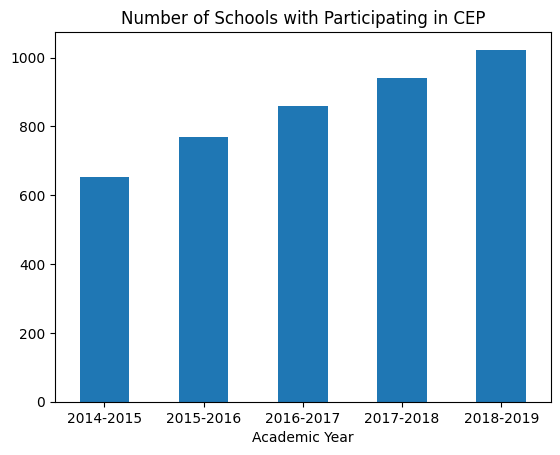

In [65]:
# bar graph cep schools per year
school_df.groupby("school_year")["cep"].sum().plot.bar(
    title="Number of Schools with Participating in CEP",
    rot=0,
    xlabel="Academic Year"
)

### Function to Estimate Effects

In [66]:
# import difference-in-differences (did) library
# %pip install moderndid
import moderndid as did

In [67]:
# first year each school adopted cep
first_cep_year = (
    school_df.loc[school_df["cep"]]
    .groupby("school_id")["school_year"]
    .min()
)

school_df["first_cep_year"] = school_df["school_id"].map(first_cep_year)

In [68]:
# convert year to integer
school_df["year_num"] = (
    school_df["school_year"]
    .str[5:]
    .astype(int)
)

# convert first cep year to integer
school_df["first_cep_year_num"] = (
    school_df["first_cep_year"]
    .str[5:]
    .astype("Int64")
)

In [69]:
# create integer school_id
school_df["school_id_num"] = (
    pd.factorize(school_df["school_id"], sort=True)[0] + 1
)

In [70]:
# function to estimate overall average treatment effect of cep adoption on cep schools (att)
def run_cep_did(school_df, outcome):

    # filter dataframe to rows with the outcome
    outcome_df = school_df.loc[
        school_df[outcome].notna()
        & (
            school_df["first_cep_year_num"].isna() |
            school_df["first_cep_year_num"].between(2015, 2017)
        )
    ].copy()

    # create cohort column (0 = never adopted cep)
    outcome_df["cohort"] = (
        outcome_df["first_cep_year_num"]
        .fillna(0)
        .astype(int)
    )

    # sort by school and year
    outcome_df = outcome_df.sort_values(
        by=["school_id_num", "year_num"]
    )

    # run did analysis
    att_test = did.att_gt(
        yname=outcome,
        tname="year_num",
        idname="school_id_num",
        gname="cohort",
        data=outcome_df,
        panel=True,
        allow_unbalanced_panel=False,
        control_group="nevertreated"
    )

    # aggregate average treatment effect
    att_simple = did.aggte(
        MP=att_test,
        type="simple"
    )

    # extract results
    att = float(att_simple.overall_att)
    se = float(att_simple.overall_se)

    # compute confidence interval
    ci_lower = att - 1.96 * se
    ci_upper = att + 1.96 * se

    # determine direction of effect
    if att > 0:
        direction = "positive"
    elif att < 0:
        direction = "negative"
    else:
        direction = "zero"

    # return results
    return {
        "outcome": outcome,
        "att": att,
        "std_error": se,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "significant": ci_lower > 0 or ci_upper < 0,
        "direction": direction
    }

## Keystone Exam

### Distribution

<Axes: title={'center': 'Algebra Keystone Exam Placements'}, xlabel='Academic Year', ylabel='Percentage'>

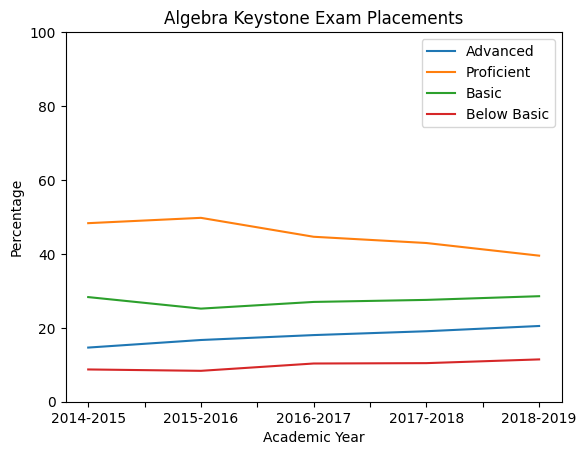

In [71]:
# math exam placements per year
school_df.groupby("school_year")[[
    "advanced_pct_algebra_all",
    "proficient_pct_algebra_all",
    "basic_pct_algebra_all",
    "below_basic_pct_algebra_all"
]].mean().round(2).rename(columns={
    "advanced_pct_algebra_all": "Advanced",
    "proficient_pct_algebra_all": "Proficient",
    "basic_pct_algebra_all": "Basic",
    "below_basic_pct_algebra_all": "Below Basic"
}).plot.line(
    ylim=(0,100),
    title="Algebra Keystone Exam Placements",
    xlabel="Academic Year",
    ylabel="Percentage"
)

<Axes: title={'center': 'Biology Keystone Exam Placements'}, xlabel='Academic Year', ylabel='Percentage'>

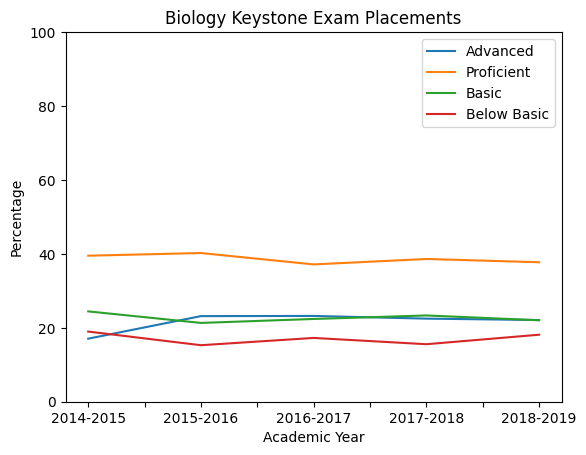

In [72]:
# bio exam placements per year
school_df.groupby("school_year")[[
    "advanced_pct_bio_all",
    "proficient_pct_bio_all",
    "basic_pct_bio_all",
    "below_basic_pct_bio_all"
]].mean().round(2).rename(columns={
    "advanced_pct_bio_all": "Advanced",
    "proficient_pct_bio_all": "Proficient",
    "basic_pct_bio_all": "Basic",
    "below_basic_pct_bio_all": "Below Basic"
}).plot.line(
    ylim=(0,100),
    title="Biology Keystone Exam Placements",
    xlabel="Academic Year",
    ylabel="Percentage"
)

<Axes: title={'center': 'Literature Keystone Exam Placements'}, xlabel='Academic Year', ylabel='Percentage'>

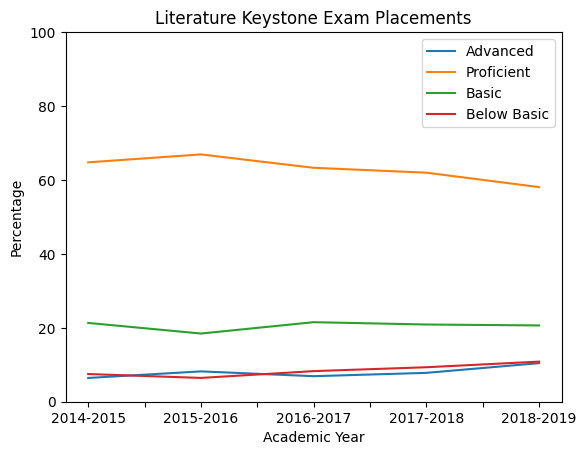

In [73]:
# lit exam placements per year
school_df.groupby("school_year")[[
    "advanced_pct_lit_all",
    "proficient_pct_lit_all",
    "basic_pct_lit_all",
    "below_basic_pct_lit_all"
]].mean().round(2).rename(columns={
    "advanced_pct_lit_all": "Advanced",
    "proficient_pct_lit_all": "Proficient",
    "basic_pct_lit_all": "Basic",
    "below_basic_pct_lit_all": "Below Basic"
}).plot.line(
    ylim=(0,100),
    title="Literature Keystone Exam Placements",
    xlabel="Academic Year",
    ylabel="Percentage"
)

### Estimate Effects of Universal Free Meal of Exam Placements

In [74]:
# list of all potential exam outcomes
exam_outcome_list = [
    "advanced_pct_lit_all", "advanced_pct_lit_disadvantaged",
    "advanced_pct_algebra_all", "advanced_pct_algebra_disadvantaged",
    "advanced_pct_bio_all", "advanced_pct_bio_disadvantaged",
    "proficient_pct_lit_all", "proficient_pct_lit_disadvantaged",
    "proficient_pct_algebra_all", "proficient_pct_algebra_disadvantaged",
    "proficient_pct_bio_all", "proficient_pct_bio_disadvantaged",
    "basic_pct_lit_all", "basic_pct_lit_disadvantaged",
    "basic_pct_algebra_all", "basic_pct_algebra_disadvantaged",
    "basic_pct_bio_all", "basic_pct_bio_disadvantaged",
    "below_basic_pct_lit_all", "below_basic_pct_lit_disadvantaged",
    "below_basic_pct_algebra_all", "below_basic_pct_algebra_disadvantaged",
    "below_basic_pct_bio_all", "below_basic_pct_bio_disadvantaged"
]

In [75]:
# calculate att of cep on each possible exam outcome
exam_att_list = []

for exam_outcome in exam_outcome_list:
    exam_att_list.append(run_cep_did(school_df, exam_outcome))

exam_att_df = pd.DataFrame(exam_att_list)

/usr/local/lib/python3.13/dist-packages/moderndid/core/preprocess/builders.py:130: UserWarning: 110 units were already treated in the first period and will be dropped
  warnings.warn(warning)
/usr/local/lib/python3.13/dist-packages/moderndid/core/preprocess/builders.py:130: UserWarning: 79 units have unbalanced observations and will be dropped
  warnings.warn(warning)
/usr/local/lib/python3.13/dist-packages/moderndid/core/preprocess/transformers.py:166: UserWarning: Dropped 110 units that were already treated in the first period
  warnings.warn(f"Dropped {n_early} units that were already treated in the first period")
/usr/local/lib/python3.13/dist-packages/moderndid/core/preprocess/transformers.py:237: UserWarning: Dropped 54 units while converting to balanced panel
  warnings.warn(f"Dropped {n_old - n_new} units while converting to balanced panel")
/usr/local/lib/python3.13/dist-packages/moderndid/core/preprocess/builders.py:130: UserWarning: 109 units were already treated in the firs

In [76]:
# view all results
exam_att_df.sort_values(by="significant", ascending=False).round(2)

,outcome,att,std_error,ci_lower,ci_upper,significant,direction
0,advanced_pct_lit_all,-1.68,0.58,-2.82,-0.55,True,negative
20,below_basic_pct_algebra_all,2.24,1.08,0.13,4.35,True,positive
19,below_basic_pct_lit_disadvantaged,3.45,1.38,0.75,6.15,True,positive
18,below_basic_pct_lit_all,3.30,1.07,1.19,5.40,True,positive
1,advanced_pct_lit_disadvantaged,-0.67,0.43,-1.51,0.16,False,negative
22,below_basic_pct_bio_all,1.66,1.76,-1.78,5.11,False,positive
21,below_basic_pct_algebra_disadvantaged,2.60,1.42,-0.19,5.39,False,positive
17,basic_pct_bio_disadvantaged,0.00,1.98,-3.89,3.89,False,positive
16,basic_pct_bio_all,0.82,1.42,-1.97,3.60,False,positive
15,basic_pct_algebra_disadvantaged,-1.17,1.83,-4.77,2.42,False,negative


In [77]:
# view significant results
exam_att_df[exam_att_df["significant"] == True].round(2)

,outcome,att,std_error,ci_lower,ci_upper,significant,direction
0,advanced_pct_lit_all,-1.68,0.58,-2.82,-0.55,True,negative
18,below_basic_pct_lit_all,3.30,1.07,1.19,5.40,True,positive
19,below_basic_pct_lit_disadvantaged,3.45,1.38,0.75,6.15,True,positive
20,below_basic_pct_algebra_all,2.24,1.08,0.13,4.35,True,positive


## Dropouts

### Distribution

<Axes: title={'center': 'Dropout Rate'}, xlabel='Academic Year', ylabel='Percentage'>

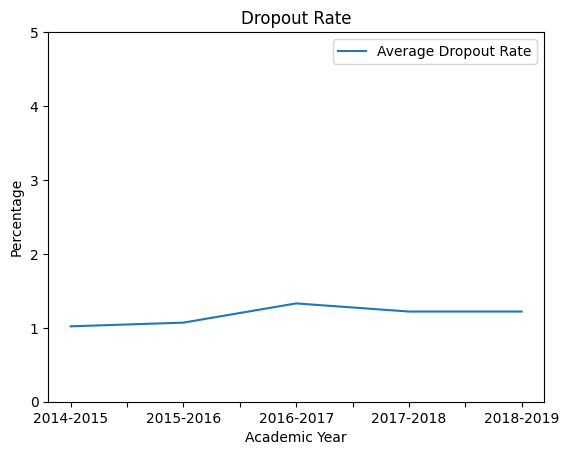

In [78]:
school_df.groupby("school_year")[["dropout_pct"]].mean().round(2).rename(columns={"dropout_pct": "Average Dropout Rate"}).plot.line(
    ylim=(0,5),
    title="Dropout Rate",
    xlabel="Academic Year",
    ylabel="Percentage"
)

### Estimate Effects of Universal Free Meal on Dropouts

In [79]:
# calculate att of cep on droprate rate
dropout_att_df = pd.DataFrame([run_cep_did(school_df, "dropout_pct")])

/usr/local/lib/python3.13/dist-packages/moderndid/core/preprocess/builders.py:130: UserWarning: 298 units were already treated in the first period and will be dropped
  warnings.warn(warning)
/usr/local/lib/python3.13/dist-packages/moderndid/core/preprocess/builders.py:130: UserWarning: 180 units have unbalanced observations and will be dropped
  warnings.warn(warning)
/usr/local/lib/python3.13/dist-packages/moderndid/core/preprocess/transformers.py:166: UserWarning: Dropped 298 units that were already treated in the first period
  warnings.warn(f"Dropped {n_early} units that were already treated in the first period")
/usr/local/lib/python3.13/dist-packages/moderndid/core/preprocess/transformers.py:237: UserWarning: Dropped 137 units while converting to balanced panel
  warnings.warn(f"Dropped {n_old - n_new} units while converting to balanced panel")


In [80]:
# view results
dropout_att_df.round(2)

,outcome,att,std_error,ci_lower,ci_upper,significant,direction
0,dropout_pct,-0.04,0.13,-0.31,0.22,False,negative
